In [1]:
import numpy as np
import pandas as pd
import h5py
import os
import sys

import matplotlib.pyplot as plt
from matplotlib import cm
import plotly.graph_objects as go

# sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
sys.path.insert(0, "..")
from plot_style import *

from eazy import photoz
from eazy import hdf5 as eazyh5

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits

from scipy import stats

In [2]:
main_dir = "/Users/jordan/Documents/Epochs/source_inject/"
fname = "smiles"

In [3]:
astro_cat = pd.read_csv(
    os.path.join(main_dir, fname, f"{fname}_mock_cat.csv")
)
pro_fake_segstats = pd.read_csv(
    os.path.join(main_dir, fname, f"{fname}_mock_all_segstats.csv")
)
pro_recovered_segstats = pd.read_csv(
    os.path.join(main_dir, fname, f"{fname}_mock_recovered_segstats.csv")
)

In [4]:
eazy_out = eazyh5.initialize_from_hdf5(
    h5file=os.path.join(main_dir, fname, "eazy", f"{fname}_zphot.out.h5")
)

set param: ADD_CGM y
set param: APPLY_IGM y
set param: APPLY_PRIOR y
set param: ARRAY_NBITS 32.0
set param: BINARY_OUTPUT y
set param: CACHE_FILE photz.tempfilt
set param: CATALOG_FILE /Users/jordan/Documents/Epochs/source_inject/smiles/smiles_mock_eazy_photometry.csv
set param: CATALOG_FORMAT ascii.commented_header
set param: CAT_HAS_EXTCORR True
set param: CHI2_SCALE 1.0
set param: DUMP_TEMPLATE_CACHE n
set param: FILTERS_RES FILTER.RES.latest
set param: FILTER_FORMAT 1.0
set param: FITTER nnls
set param: FIX_ZSPEC n
set param: GET_ZP_OFFSETS n
set param: H0 70.0
set param: HESS_THRESHOLD 1.0
set param: IGM_SCALE_TAU 1.0
set param: MAGNITUDES n
set param: MAIN_OUTPUT_FILE /Users/jordan/Documents/Epochs/source_inject/smiles/eazy/smiles_zphot.out
set param: MW_EBV 0.0
set param: NMF_TOLERANCE 0.0001
set param: NOT_OBS_THRESHOLD -90
set param: N_MIN_COLORS 5.0
set param: OBS_SED_FILE n
set param: OMEGA_L 0.7
set param: OMEGA_M 0.3
set param: OUTPUT_DIRECTORY /Users/jordan/Documents/Epoc

Set sys_err = 0.00 (positive=True)
Template grid: templates/LarsonSEDTemplates/tweak_fsps_QSF_12_v3_newtemplates.param (this may take some time)
TemplateGrid: user-provided tempfilt_data
Process templates: 0.068 s


371it [00:01, 300.34it/s]


h5: read tweak_fsps_QSF_12_v3_001.dat
h5: read tweak_fsps_QSF_12_v3_002.dat
h5: read tweak_fsps_QSF_12_v3_003.dat
h5: read tweak_fsps_QSF_12_v3_004.dat
h5: read tweak_fsps_QSF_12_v3_005.dat
h5: read tweak_fsps_QSF_12_v3_006.dat
h5: read tweak_fsps_QSF_12_v3_007.dat
h5: read tweak_fsps_QSF_12_v3_008.dat
h5: read tweak_fsps_QSF_12_v3_009.dat
h5: read tweak_fsps_QSF_12_v3_010.dat
h5: read tweak_fsps_QSF_12_v3_011.dat
h5: read tweak_fsps_QSF_12_v3_012.dat
h5: read binc100z001age6_cloudy.dat
h5: read binc100z001age65_cloudy.dat
h5: read binc100z001age7_cloudy.dat
h5: read binc100z001age6.dat
h5: read binc100z001age65.dat
h5: read binc100z001age7.dat
fit_best: 0.6 s (n_proc=1,  NOBJ=19619)


/Users/jordan/miniconda3/envs/eazy/lib/python3.14/site-packages/IPython/core/events.py:100: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  func(*args, **kwargs)
/Users/jordan/miniconda3/envs/eazy/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


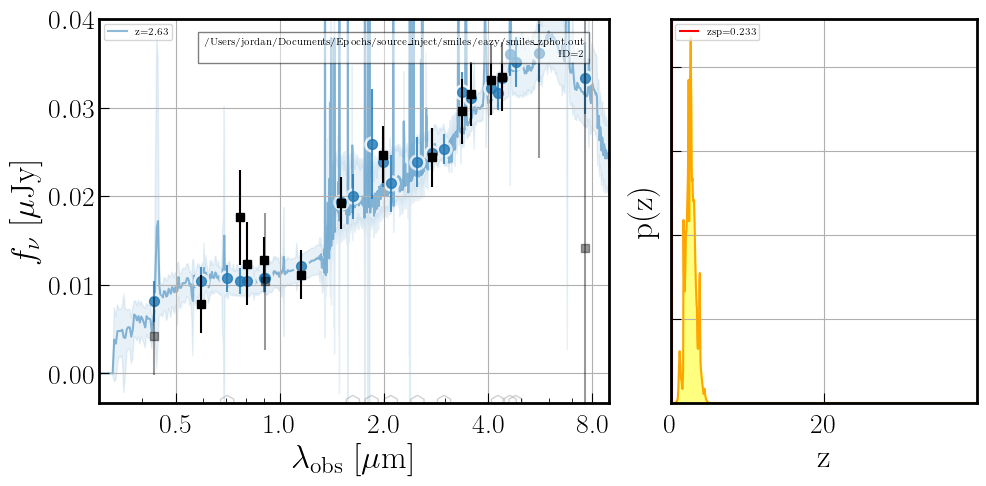

In [13]:
fig = eazy_out.show_fit(id = 2, figsize = (10,5), show_fnu=True)

In [16]:
def compute_sigmaNMAD(zspec, zphot, zphot_thresh = 0):
    idx = zphot >= zphot_thresh
    deltaz = zphot[idx] - zspec[idx]
    sigmaNMAD = 1.48 * np.median( np.abs( (deltaz - np.median(deltaz)) / (1+zspec[idx]) ) )
    return sigmaNMAD


def compute_outliers(zspec, zphot, thresh = 3, zphot_thresh = 0):
    idx = zphot >= zphot_thresh
    sigma = compute_sigmaNMAD(zspec[idx], zphot[idx])
    deltaz = abs(zphot[idx] - zspec[idx])

    Noutlier = sum(deltaz/(1+zspec[idx]) > thresh*sigma)

    if len(zspec) <= 0:
        outlier_frac = 0
    else:
        outlier_frac = Noutlier / len(zspec[idx])

    return outlier_frac, Noutlier, len(zspec[idx]), thresh

def compute_outliers_percent(zspec, zphot, thresh = 0.15, zphot_thresh = 0):
    idx = zphot >= zphot_thresh

    deltaz = abs(zphot[idx] - zspec[idx])
    Noutlier = sum(deltaz > thresh * (1+zspec[idx]))

    outlier_frac = Noutlier / len(zspec[idx])
    return outlier_frac

In [41]:
sigmaNMAD = compute_sigmaNMAD(zphot=eazy_out.zml, zspec=astro_cat['z'], zphot_thresh=0)
outliers = compute_outliers(zphot=eazy_out.zml, zspec=astro_cat['z'], zphot_thresh=0)
outliers_pc = compute_outliers_percent(zphot=eazy_out.zml, zspec=astro_cat['z'], zphot_thresh=0)

print(sigmaNMAD)
print(outliers)
print(outliers_pc)

Ntemplates = np.sum(eazy_out.coeffs_best > 0, axis = 1)
Nfluxes = np.sum(eazy_out.efnu > -90, axis = 1)

0.05659319796041447
(0.24132714804356595, 2393, 9916, 3)
0.25060508269463494


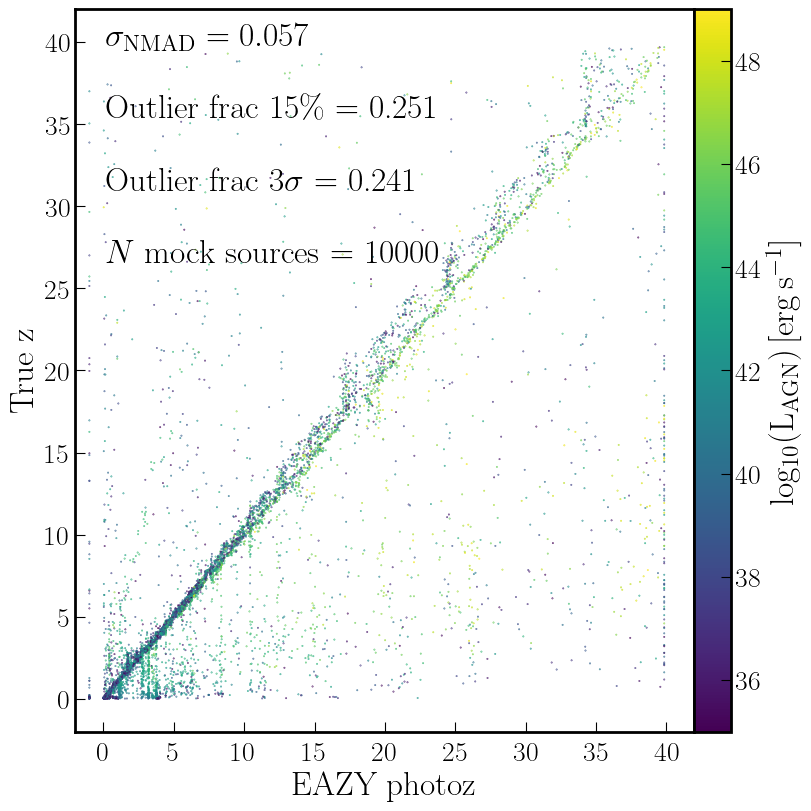

In [42]:
fig, ax = plt.subplots(1, 1, figsize = (8,8))

sc_ = ax.scatter(
    eazy_out.zbest, 
    astro_cat['z'],
    c = np.log10(astro_cat["AGNlum"]),
    marker = '.', 
    s = 0.5,
    # color = 'black'
)
ax.text(
    0.05, 0.95, rf"$\sigma_{{\mathrm{{NMAD}}}} = {sigmaNMAD:.3f}$", transform = ax.transAxes
)
ax.text(
    0.05, 0.85, rf"Outlier frac 15\% = {outliers_pc:.3f}", transform = ax.transAxes
)
ax.text(
    0.05, 0.75, rf"Outlier frac {outliers[3]}$\sigma$ = {outliers[0]:.3f}", transform = ax.transAxes
)
ax.text(
    0.05, 0.65, rf"$N$ mock sources = 10000", transform = ax.transAxes
)

ax.set_ylim([-2,42])
ax.set_xticks(ax.get_yticks())
ax.set_xlim([-2,42])
ax.set_xlabel("EAZY photoz")
ax.set_ylabel("True z")
# plt.scatter(
#     astro_cat['z'][idx_selected],
#     eazy_out.zbest[idx_selected], 
#     marker = "."
# )

fig.colorbar(sc_, ax=ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0)
# fig.savefig(
#     "/Users/jordan/Documents/Epochs/plots/completeness/zeazy_ztrue.png", bbox_inches="tight", dpi = 240
# )

In [9]:
zbins = np.arange(0, 40, 1.0)
zmids = (zbins[1:] + zbins[:-1])/2.0

magbins = np.arange(10, 40, 1.0)
magmids = (magbins[1:] + magbins[:-1])/2.0

completeness_array = np.zeros(shape = (len(magmids), len(zmids)))
contamination_array = np.zeros(shape = (len(magmids), len(zmids)))

for i in range(len(magmids)):
    for j in range(len(zmids)):

        detect_idx = (astro_cat["recoveredmag"] >= magbins[i]) & (astro_cat["recoveredmag"] < magbins[i+1]) & \
            (eazy_out.zbest >= zbins[j]) & (eazy_out.zbest < zbins[j+1])
        
        true_idx = (astro_cat["detmag"] >= magbins[i]) & (astro_cat["detmag"] < magbins[i+1]) & \
            (astro_cat["z"] >= zbins[j]) & (astro_cat["z"] < zbins[j+1])

        idx_bad_fit = (1 - stats.chi2.cdf(match_chi2[detect_idx], df = Nfluxes[detect_idx] - Ntemplates[detect_idx] - 1.0) < 0.05) | (eazy_out.zbest[detect_idx] == -1) | (astro_cat["detected"][detect_idx] == 0)

        outliers = compute_outliers(
            zphot=eazy_out.zbest[detect_idx][~idx_bad_fit],
            zspec=astro_cat["z"][detect_idx][~idx_bad_fit]
        )

        Nselect = np.sum(~idx_bad_fit) - outliers[1]
        Ntrue = np.sum(true_idx)
        completeness = Nselect / Ntrue
        
        if Ntrue == 0:
            completeness = np.nan
        completeness_array[i,j] = completeness
        completeness_array[i,j] = completeness

NameError: name 'match_chi2' is not defined

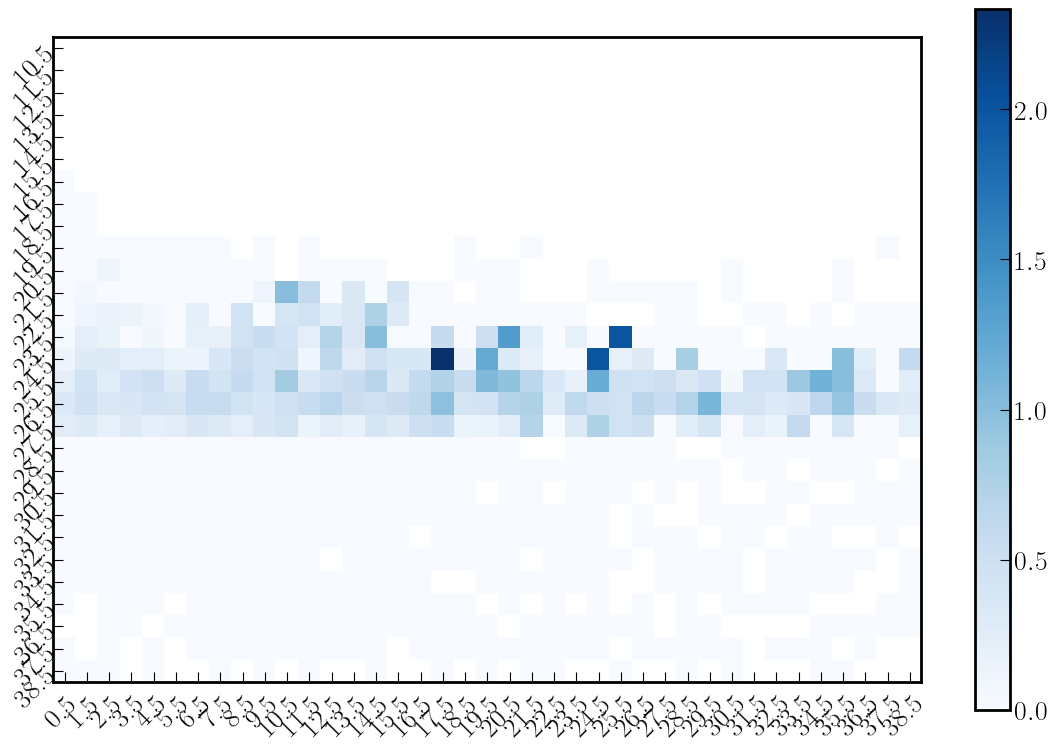

In [63]:
fig, ax = plt.subplots(figsize = (12,8))

mag_ids = np.where((magmids >= 10) & (magmids <= 40))[0]
z_ids = np.where((zmids >= 0) & (zmids <= 40))[0]

im = ax.imshow(
    completeness_array[np.ix_(mag_ids, z_ids)], 
    cmap='Blues'
)

# ax.set_xlim([0,10])
# ax.set_ylim([18,30])
ax.set_yticks(range(len(magmids[mag_ids])), labels=magmids[mag_ids], rotation=45, ha="right", rotation_mode="anchor")
ax.set_xticks(range(len(zmids[z_ids])), labels=zmids[z_ids], rotation=45, ha="right", rotation_mode="anchor")

# ax.set_title("Harvest of local farmers (in tons/year)")
fig.colorbar(im)
fig.tight_layout()
plt.show()
